# 6 - Multi-object tracking and temporal object memory

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT.parent == ROOT:
        raise RuntimeError("run this notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)
print("python:  ", sys.version.split()[0], "->", sys.executable)

repo root: /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback
python:   3.14.4 -> /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/bin/python


In [ ]:
import collections
from dataclasses import fields, replace

import numpy as np

from perception.contracts import CaptureFrame, MemoryState, TrackLifecycle
from perception.inference import Frame, prerecorded_frames, run_inference
from perception.inference.yolo import YoloDetector
from perception.ontology import load_ontology
from perception.tracking import (
    Tracker,
    TrackerConfig,
    action_camera_shift,
    collectable_classes,
)
from perception.tracking import tracker as tracker_module
from perception.tracking.evaluation import identity_metrics
from perception.tracking.render import plot_track_timeline, render_tracks
from tests.scenes import TRACKING_SCENES, run_tracking_scene, scene_image, scene_names

import html

import matplotlib.pyplot as plt
from IPython.display import HTML, display

In [ ]:
def table(rows, columns=None):
    if not rows:
        print("(no rows)")
        return
    columns = columns or list(rows[0])
    head = "".join(
        f"<th style='text-align:left'>{html.escape(str(c))}</th>" for c in columns
    )
    body = "".join(
        "<tr>"
        + "".join(
            f"<td style='text-align:left'>{html.escape(str(r.get(c, '')))}</td>"
            for c in columns
        )
        + "</tr>"
        for r in rows
    )
    display(HTML(f"<table><tr>{head}</tr>{body}</table>"))

In [ ]:
def show_images(images, titles=(), columns=4, size=4.0):
    rows = (len(images) + columns - 1) // columns
    figure, axes = plt.subplots(
        rows, columns, figsize=(size * columns, size * rows), squeeze=False
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, list(titles) + [""] * len(images)):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
    figure.tight_layout()
    plt.show()

In [ ]:
CONFIG = TrackerConfig.from_json_file("configs/tracker.json")
ONTOLOGY = load_ontology("configs/ontology.json")
TERMINABLE = collectable_classes(ONTOLOGY)
WEIGHTS = Path("runs/detector/notebook_yolo26n_seg/weights/best.pt")
EPISODE = Path("captures/curriculum_run/rgb/curriculum-0108")                  # held-out (test split)
EVAL_EPISODES = ["curriculum-0108", "curriculum-0013", "curriculum-0062"]     # held-out, with annotations
DEVICE = "auto"
CODES = {"visible": "V", "partially_visible": "p", "occluded": "O", "out_of_view": ">", "lost": "?", "unobservable": "#", "terminated": "X"}

## State machine and configuration

In [3]:
print(tracker_module.__doc__)
table([{"setting": f.name, "value": getattr(CONFIG, f.name)} for f in fields(CONFIG)])

Multi-object tracker and temporal object memory over detector-neutral `DetectionFrame`s.

Per frame: predict every track with constant image-space velocity plus the caller's
`camera_shift` (ego-motion: how static scene content moved in the image), associate greedily (1) by IoU
with the predicted box, then (2) re-identify leftover detections against unmatched tracks by class
similarity and distance to the last-seen or predicted box (sizes within `max_scale_change`), then
decide each track's state. Both stages are class-gated: a detection of another class can only take
over a track at `relabel_iou` overlap. An unmatched detection overlapping an assigned one that much
is a duplicate and starts no track. Velocity is only measured between two un-truncated sightings.


    matched                    VISIBLE, or PARTIALLY_VISIBLE when truncated by the frame edge or
                               covered by a nearer detection (>= partial_coverage)
    frame unobservable         UNOBSERVABLE: n

setting,value
min_iou,0.1
reid_distance,1.5
reid_image_fraction,0.3
min_class_similarity,0.2
relabel_iou,0.7
max_scale_change,3.0
initial_existence,0.5
hit_gain,0.5
occluded_decay,0.98
out_of_view_decay,0.995


### Synthetic scenarios

Each scenario (`tests/fixtures/tracking_scenes/*.json`) is keyframed boxes turned into detections
and fed through the real tracker. For each: the state timeline, then the frames where a track's
state changed.

Filled rectangles show the keyframed scene objects, with nearer objects covering farther ones.
Solid outlines mark current detections; dashed outlines mark remembered tracks at their last
observed box, so a hidden goal is not drawn at a guessed position behind the wall.

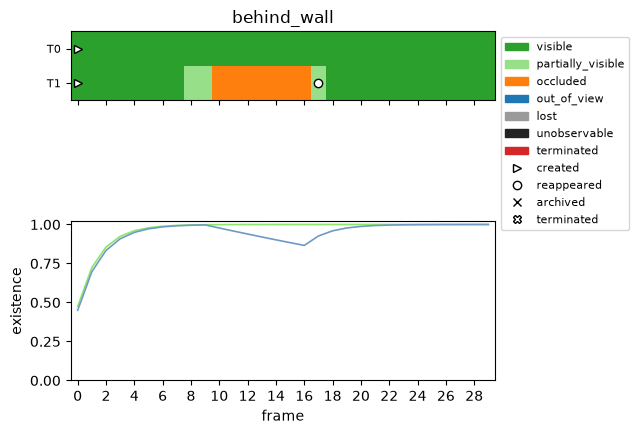

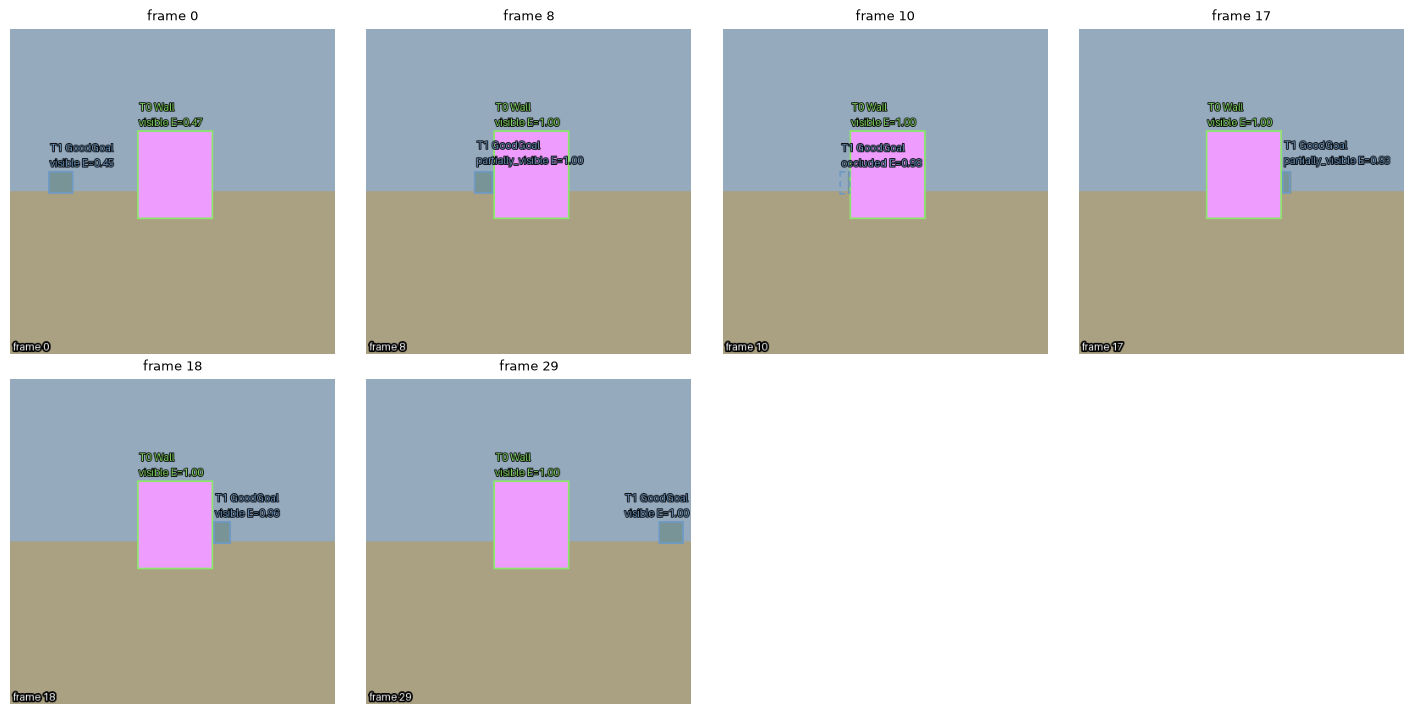

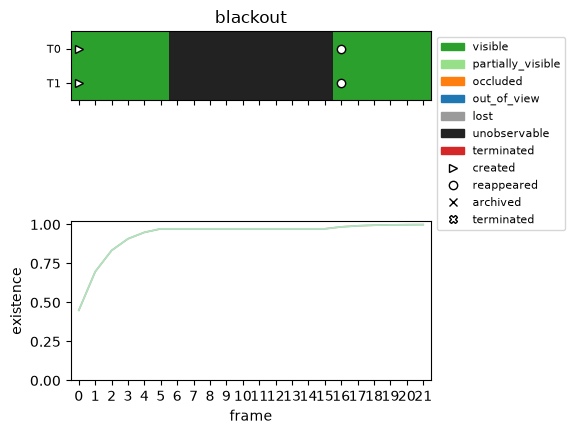

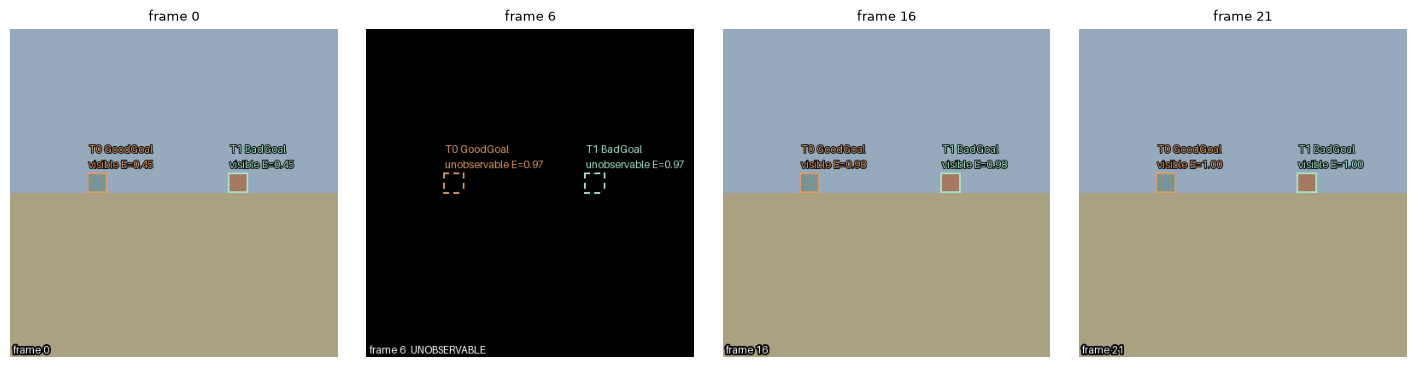

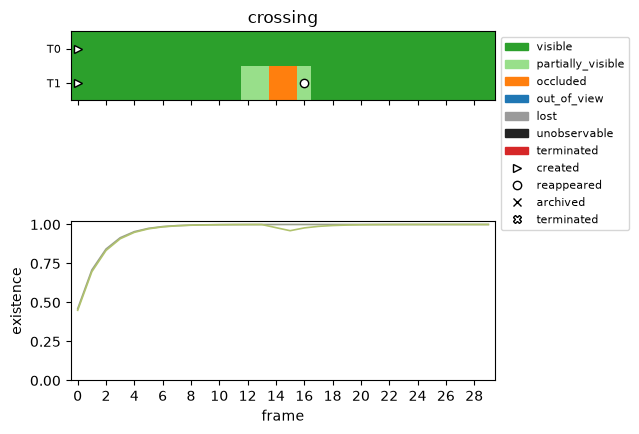

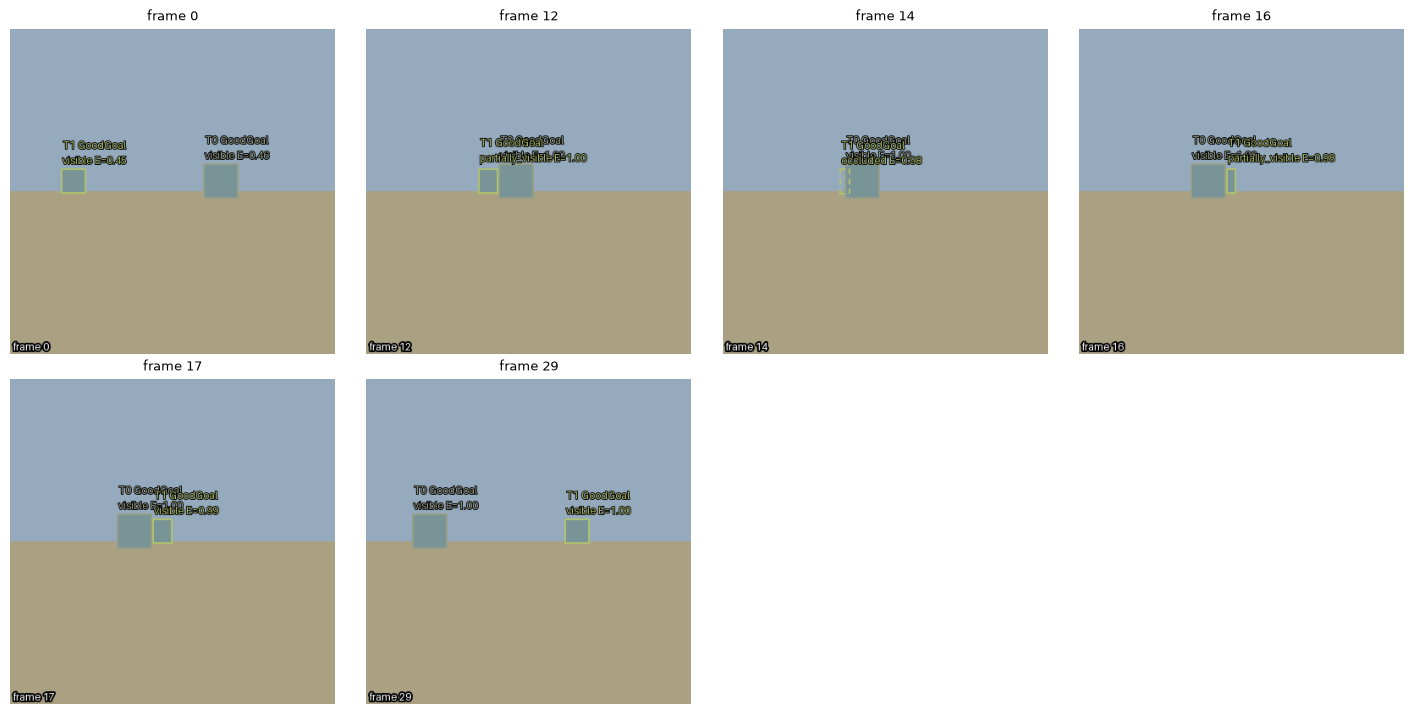

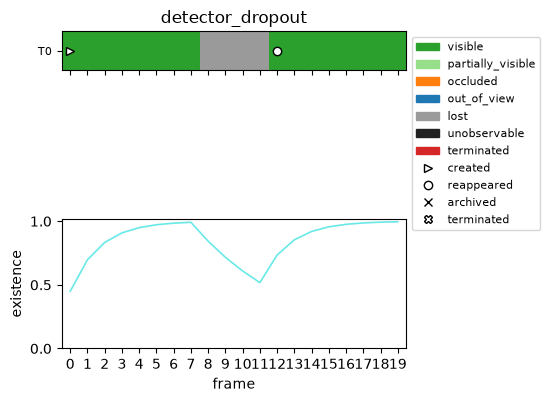

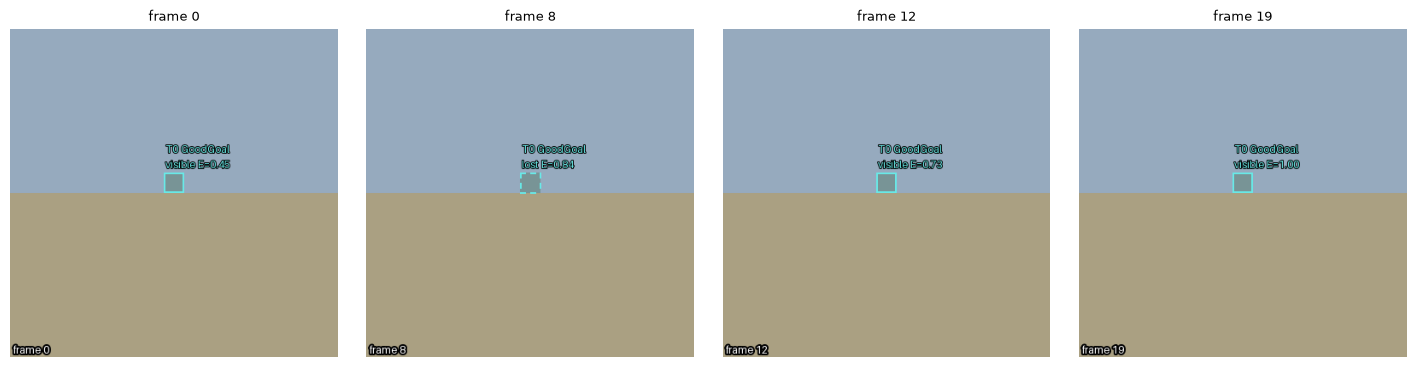

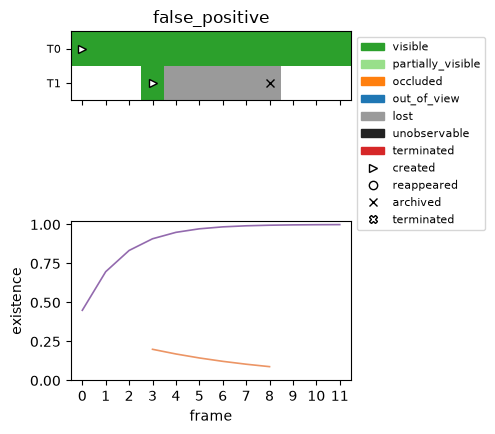

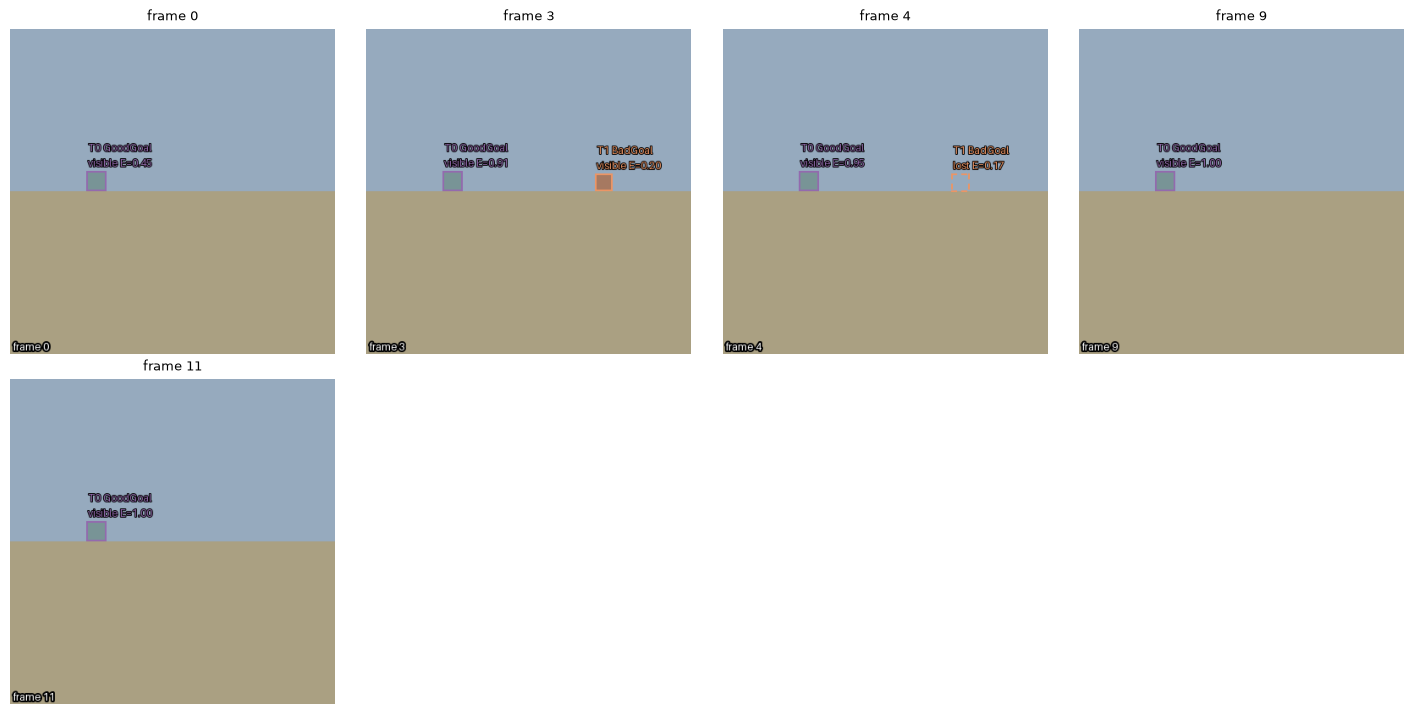

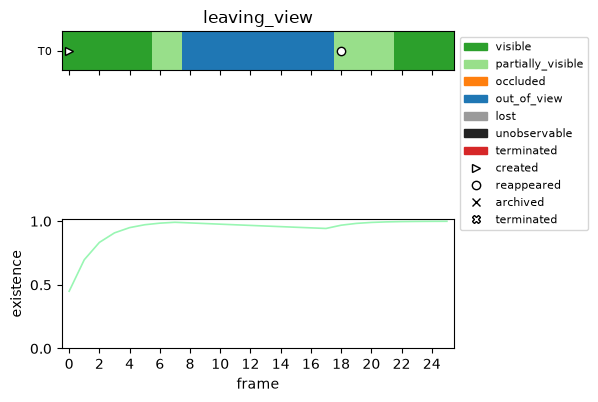

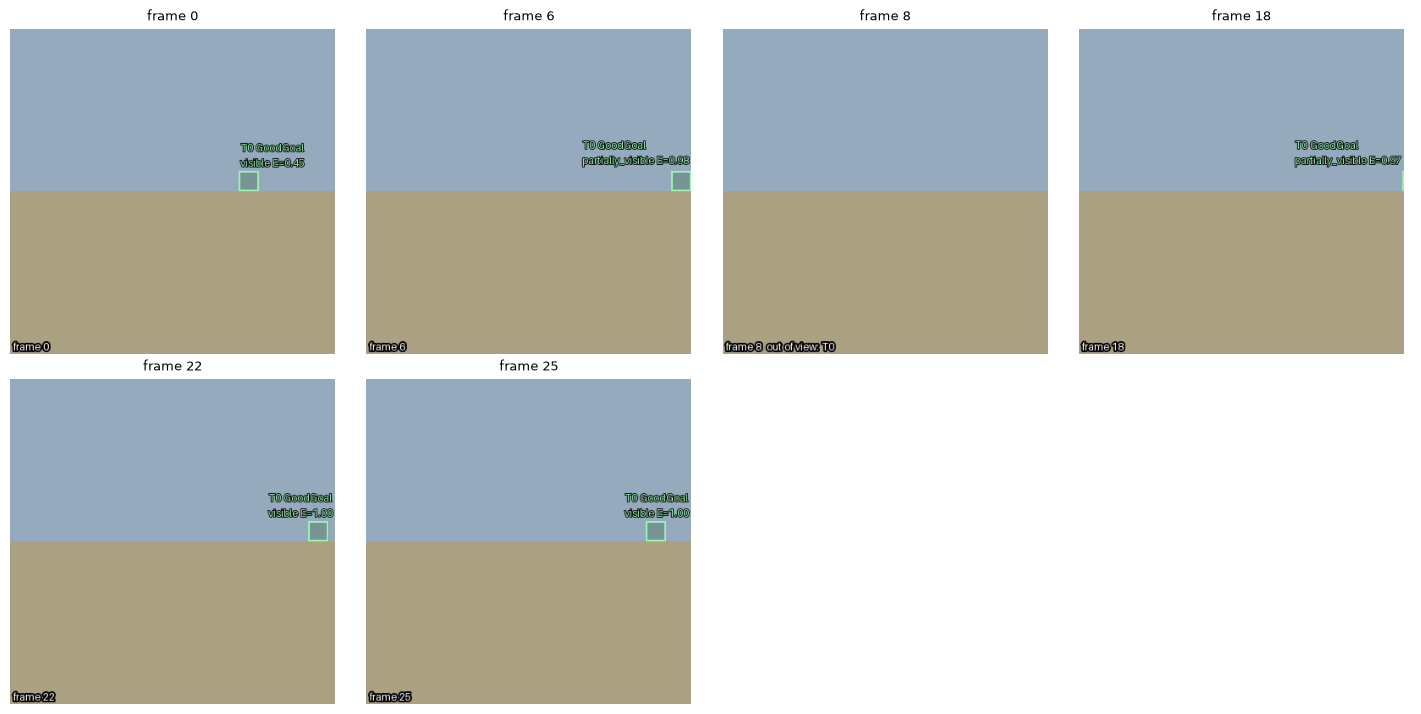

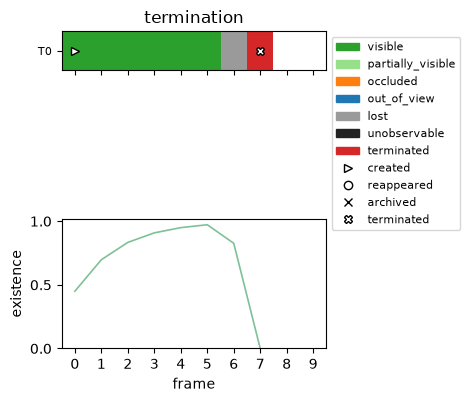

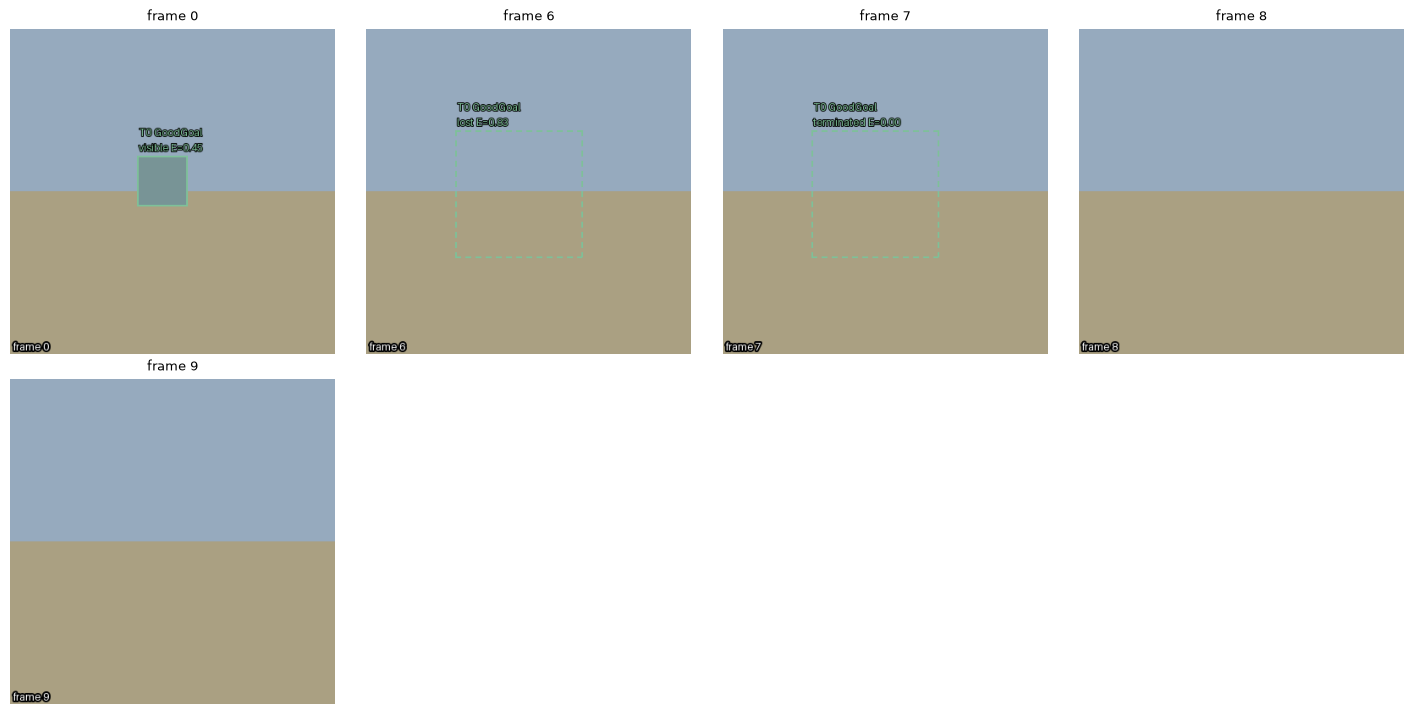

In [4]:
scenarios = {name: run_tracking_scene(name) for name in scene_names(TRACKING_SCENES)}
for name, (scene, track_frames) in scenarios.items():
    display(HTML(f"<h3>{name}</h3><p>{scene['description']}</p>"))
    plot_track_timeline(track_frames, title=name)
    plt.show()
    changes, previous = [0], {}
    for i, f in enumerate(track_frames):
        now = {t.record.track_id: t.memory.state for t in f.tracks}
        if i and now != previous:
            changes.append(i)
        previous = now
    keys = sorted(set(changes[:7] + [len(track_frames) - 1]))[:8]
    show_images([render_tracks(track_frames[i], scene_image(scene, i)) for i in keys], [f"frame {i}" for i in keys], columns=4, size=3.6)

In [5]:
rows = []
for name, (scene, track_frames) in scenarios.items():
    ids = sorted({t.record.track_id for f in track_frames for t in f.tracks})
    for track_id in ids:
        states = "".join(CODES[next(t for t in f.tracks if t.record.track_id == track_id).memory.state.value]
                         if any(t.record.track_id == track_id for t in f.tracks) else "." for f in track_frames)
        rows.append({"scenario": name, "track": track_id.rsplit(":", 1)[-1], "states per frame": states})
table(rows)

scenario,track,states per frame
behind_wall,track-0000,VVVVVVVVVVVVVVVVVVVVVVVVVVVVVV
behind_wall,track-0001,VVVVVVVVppOOOOOOOpVVVVVVVVVVVV
blackout,track-0000,VVVVVV##########VVVVVV
blackout,track-0001,VVVVVV##########VVVVVV
crossing,track-0000,VVVVVVVVVVVVVVVVVVVVVVVVVVVVVV
crossing,track-0001,VVVVVVVVVVVVppOOpVVVVVVVVVVVVV
detector_dropout,track-0000,VVVVVVVV????VVVVVVVV
false_positive,track-0000,VVVVVVVVVVVV
false_positive,track-0001,...V?????...
leaving_view,track-0000,VVVVVVpp>>>>>>>>>>ppppVVVV


## A captured Animal-AI episode (held out from detector training)

Detection + tracking on the RGB frames only. Prerecorded captures carry no agent actions, so no
camera-shift (ego-motion) is applied here; the evaluation section below shows its effect.

In [6]:
yolo = YoloDetector(WEIGHTS, device=DEVICE)
images, real = {}, []

def keep(frame, track_frame):
    images[frame.stamp.frame_index] = frame.image
    real.append(track_frame)

summary = run_inference(yolo, prerecorded_frames(EPISODE), ontology=ONTOLOGY,
                        tracker=Tracker(CONFIG, TERMINABLE), on_tracks=keep)
print(f"{EPISODE.name}: {summary['frames']} frames, {summary['detections']} detections, "
      f"{len({t.record.track_id for f in real for t in f.tracks})} tracks")

curriculum-0108: 430 frames, 1486 detections, 71 tracks


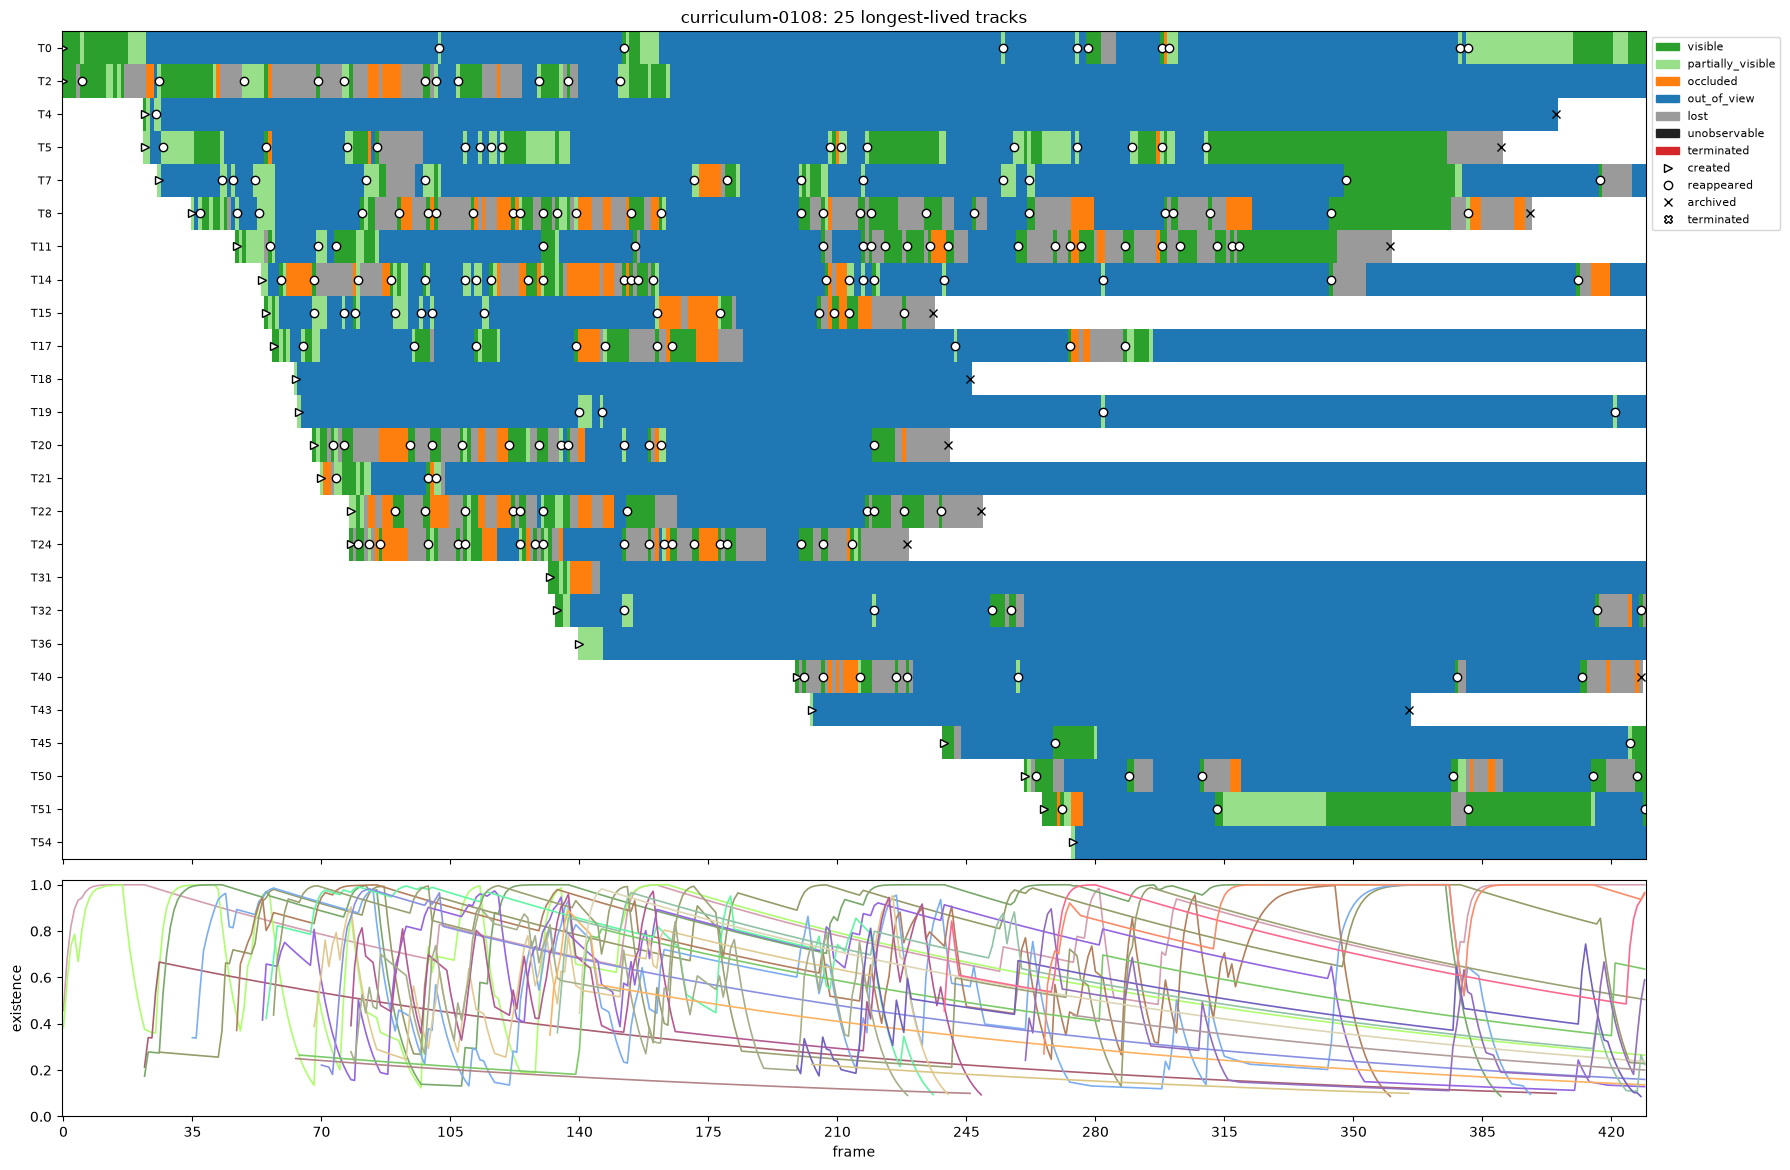

In [7]:
plot_track_timeline(real, max_tracks=25, title=f"{EPISODE.name}: 25 longest-lived tracks")
plt.show()

curriculum-0108:track-0005 reappears at frame 55 after 12 unseen frames


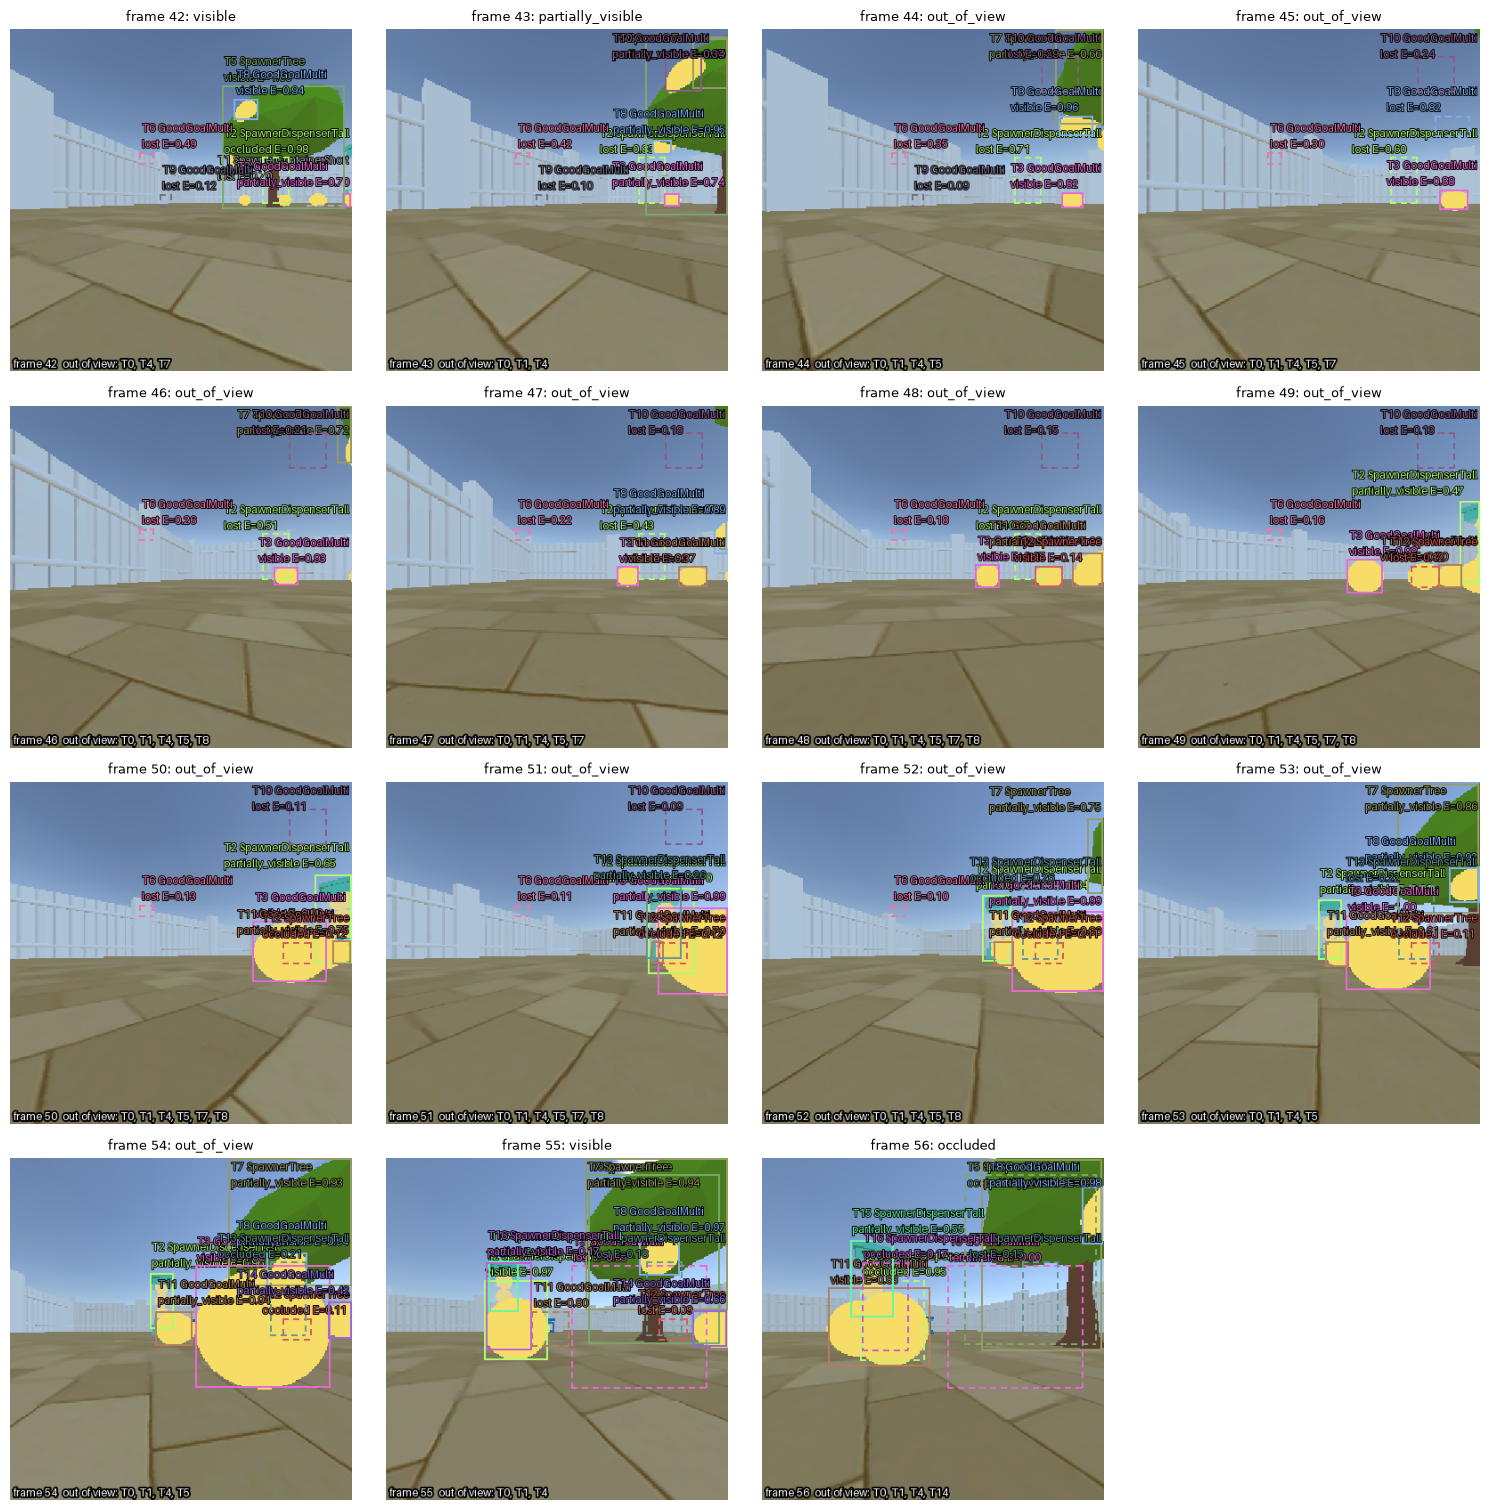

In [8]:
# a long-lived track that went unseen for 4-12 frames and came back under the same ID
best = None
for i, f in enumerate(real):
    for t in f.tracks:
        if t.record.lifecycle is TrackLifecycle.REAPPEARED and t.hits >= 15:
            seen = [j for j in range(i) if any(u.record.track_id == t.record.track_id and u.record.detector_id for u in real[j].tracks)]
            gap = i - max(seen) if seen else 0
            if 4 <= gap <= 12 and (best is None or gap > best[2]):
                best = (i, t.record.track_id, gap)
if best:
    i, track_id, gap = best
    print(f"{track_id} reappears at frame {real[i].stamp.frame_index} after {gap} unseen frames")
    window = list(range(max(i - gap - 1, 0), min(i + 2, len(real))))
    show_images([render_tracks(real[j], images[real[j].stamp.frame_index]) for j in window],
                [f"frame {real[j].stamp.frame_index}: " + next((t.memory.state.value for t in real[j].tracks if t.record.track_id == track_id), "gone")
                 for j in window], columns=4, size=3.8)

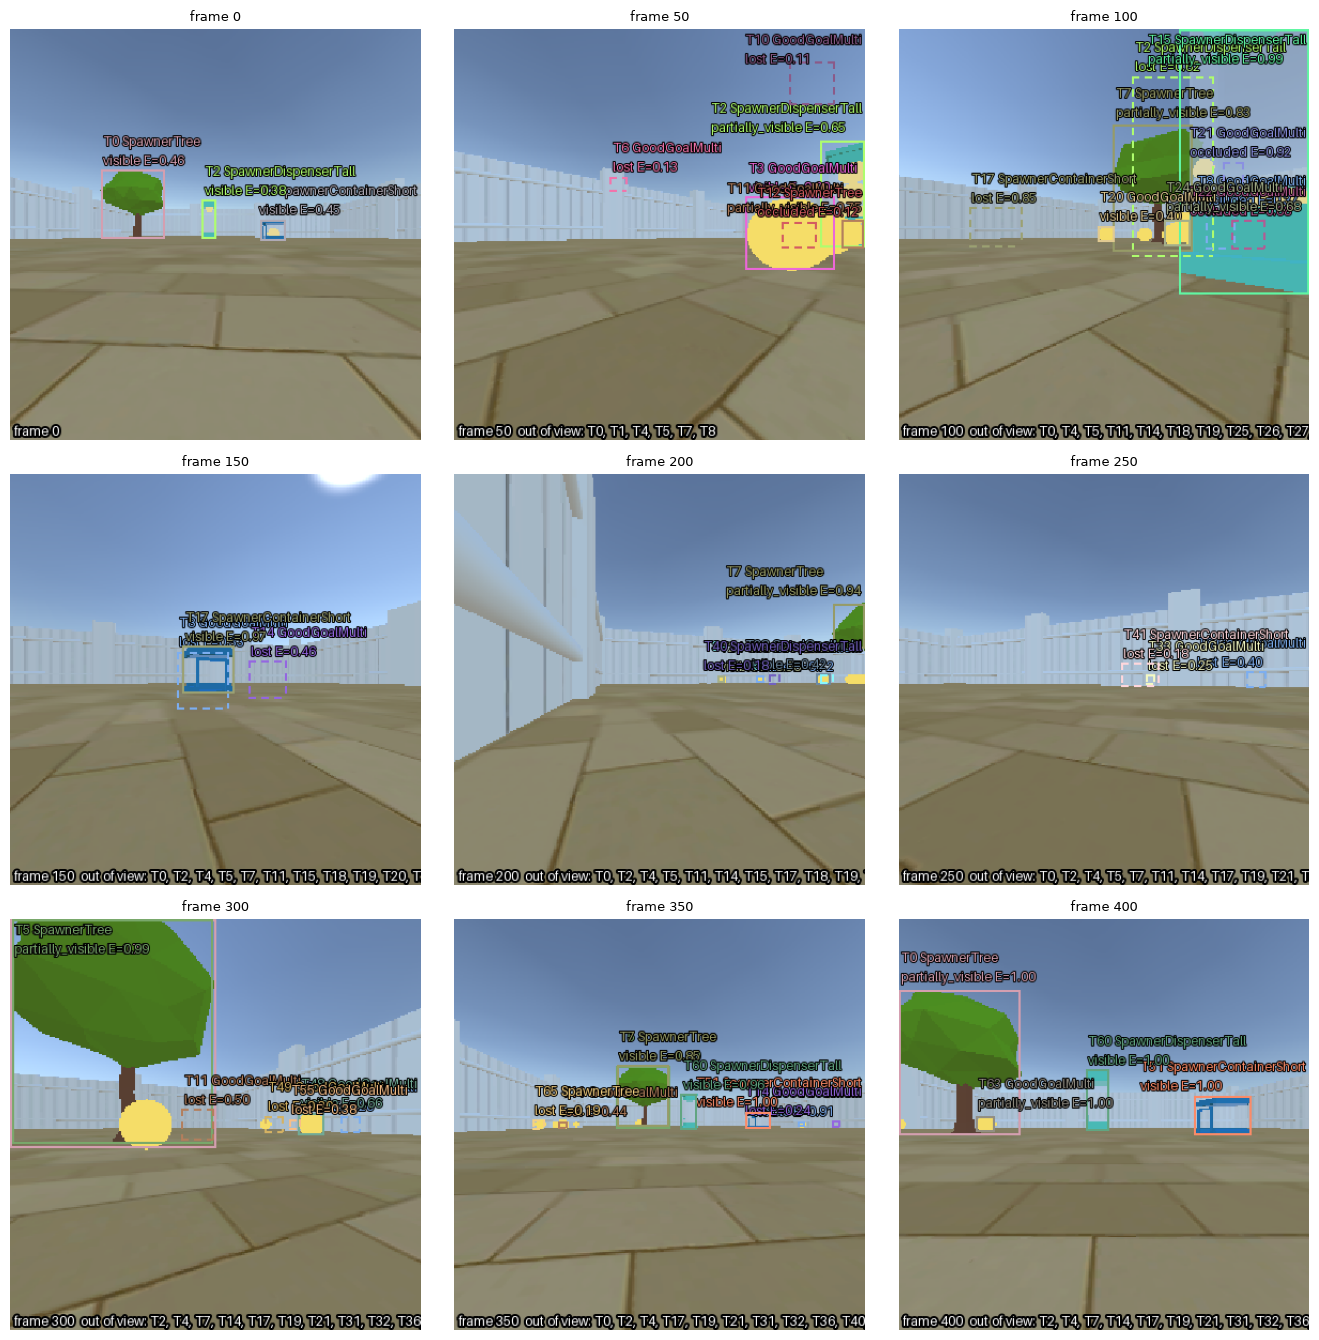

In [9]:
picks = list(range(0, len(real), 50))
show_images([render_tracks(real[j], images[real[j].stamp.frame_index]) for j in picks],
            [f"frame {real[j].stamp.frame_index}" for j in picks], columns=3, size=4.5)

In [10]:
table([{"lifecycle event": k, "count": v} for k, v in summary["tracking"]["lifecycle_events"].items()])
states = collections.Counter(t.memory.state.value for f in real for t in f.tracks)
table([{"state": k, "track-frames": v} for k, v in states.most_common()])
print("tracker ms/frame:", {k: round(v, 2) for k, v in summary["latency_ms"]["tracking"].items()})

lifecycle event,count
created,71
updated,1114
missed,7238
reappeared,284
archived,51
terminated,1


state,track-frames
out_of_view,5963
lost,1012
visible,1011
partially_visible,458
occluded,314
terminated,1


tracker ms/frame: {'mean': 1.64, 'p50': 1.54, 'p95': 2.41, 'max': 34.28}


## Offline evaluation against ground-truth identities

**Evaluation only.** This section reads the captures' privileged annotations (instance IDs, and
the agent's recorded actions to stand in for the actions a live agent knows), which the runtime
path never does. Detections are computed once per episode, then the tracker is re-run with
different settings. Metric: distinct track IDs each ground-truth object received (1 is perfect),
and matched frames per ID (higher = identities last longer).

curriculum-0108: 430 frames detected


curriculum-0013: 224 frames detected


curriculum-0062: 161 frames detected


settings,episode,objects,ID switches,IDs / object (median),IDs / object (max),matched frames / ID
default,curriculum-0108,17,295,11,18,6.8
default,curriculum-0013,7,39,4,7,18.4
default,curriculum-0062,5,42,5,9,9.0
no action ego-motion,curriculum-0108,17,309,11,20,6.6
no action ego-motion,curriculum-0013,7,36,4,6,19.7
no action ego-motion,curriculum-0062,5,40,6,7,8.4
no wide re-identification gate,curriculum-0108,17,319,11,17,6.7
no wide re-identification gate,curriculum-0013,7,43,5,9,14.2
no wide re-identification gate,curriculum-0062,5,44,5,9,8.7
faster lost decay (0.7),curriculum-0108,17,297,11,28,5.7


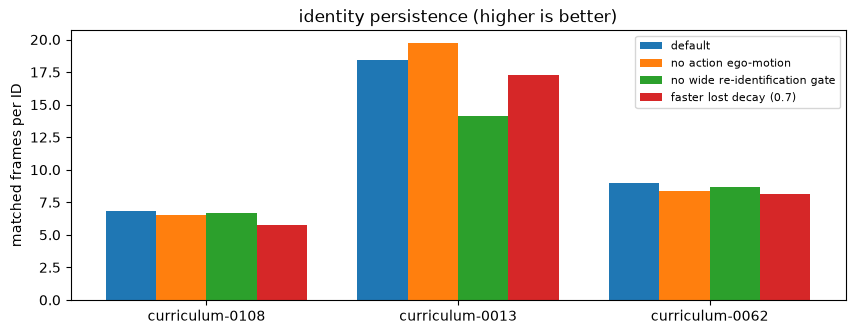

In [11]:
truth, cached = {}, {}
for name in EVAL_EPISODES:
    annotations = sorted(Path(f"captures/curriculum_run/annotations/{name}").glob("*.json"))
    truth[name] = {int(p.stem): CaptureFrame.from_json_file(p) for p in annotations}
    episode_frames = list(prerecorded_frames(Path("captures/curriculum_run/rgb") / name))
    cached[name] = (episode_frames, yolo.detect_batch(episode_frames))
    print(f"{name}: {len(episode_frames)} frames detected")

VARIANTS = {
    "default": (CONFIG, True),
    "no action ego-motion": (CONFIG, False),
    "no wide re-identification gate": (replace(CONFIG, reid_image_fraction=0.0), True),
    "faster lost decay (0.7)": (replace(CONFIG, lost_decay=0.7), True),
}
rows, metrics = [], {}
for variant, (config, ego) in VARIANTS.items():
    for name in EVAL_EPISODES:
        tracker = Tracker(config, TERMINABLE)
        episode_frames, detections = cached[name]
        out = []
        for frame, detection in zip(episode_frames, detections):
            action = truth[name][frame.stamp.frame_index].agent.recent_action if ego else None
            out.append(tracker.update(detection.frame, detection.masks,
                                      camera_shift=action_camera_shift(action, frame.image.shape[1], config)))
        m = identity_metrics(out, truth[name])
        metrics[(variant, name)] = m
        rows.append({"settings": variant, "episode": name, "objects": m["instances"], "ID switches": m["id_switches"],
                     "IDs / object (median)": m["ids_per_instance_median"], "IDs / object (max)": m["ids_per_instance_max"],
                     "matched frames / ID": f"{m['matched_frames_per_id']:.1f}"})
table(rows)
figure, ax = plt.subplots(figsize=(10, 3.5))
width = 0.8 / len(VARIANTS)
for k, variant in enumerate(VARIANTS):
    ax.bar(np.arange(len(EVAL_EPISODES)) + k * width, [metrics[(variant, n)]["matched_frames_per_id"] for n in EVAL_EPISODES],
           width, label=variant)
ax.set_xticks(np.arange(len(EVAL_EPISODES)) + 0.4 - width / 2, EVAL_EPISODES)
ax.set_ylabel("matched frames per ID"); ax.legend(fontsize=8); ax.set_title("identity persistence (higher is better)")
plt.show()

In [12]:
for name in EVAL_EPISODES:
    m = metrics[("default", name)]
    print(f"== {name}: {m['id_switches']} switches")
    table([{"cause": k, "count": v} for k, v in m["switch_causes"].items()])

== curriculum-0108: 295 switches


cause,count
previous track took another detection,101
previous track alive but unmatched (lost),86
previous track alive but unmatched (out_of_view),72
previous track alive but unmatched (occluded),20
previous track archived or terminated,16


== curriculum-0013: 39 switches


cause,count
previous track alive but unmatched (lost),17
previous track alive but unmatched (out_of_view),10
previous track took another detection,9
previous track archived or terminated,3


== curriculum-0062: 42 switches


cause,count
previous track alive but unmatched (out_of_view),17
previous track took another detection,15
previous track alive but unmatched (lost),5
previous track alive but unmatched (occluded),5
